# Qwen3-30B-A3B: TorchAO INT4 + LoRA training

SFTTrainer on physical GPU 2 / A100 40GB, existing Python 3.10. GPTQ INT4 weights repacked for TorchAO's fused Triton forward **and input-gradient backward**; no requantization or full float weight cache.

FP16 compute, FP32 LoRA parameters; rank 16, alpha 32, dropout 0, attention and experts in layers 45–47. Frozen base, no extra pruning/TL wrappers. **Batch 8 × 512** was fastest in tokens/s; 16 × 512 OOM. SDPA, no checkpointing, accumulation 1.

AdamW LR 2e-4, 5 warmup steps, cosine decay, clipping 1.0; 100 updates. Official WikiText-2 train/validation splits packed independently, EOS after nonempty records, labels retain EOS. 1,024 train blocks, fixed 32 validation blocks, seed 42. No padding.

Original `qlora-Qwen3-30B-A3B_train.ipynb` unchanged. Previous smoke results remain in `torchao_int4/`. Helpers: `train_qwen_torchao.py`, `torchao_int4.py`, `train_qwen_torchao_sft.py`.

In [1]:
import os
import sys
import json
from pathlib import Path
# Use a fresh kernel before changing visibility / dtype.
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
os.environ["COMPUTE_DTYPE"] = "fp16"
os.environ["HF_HUB_CACHE"] = "/glazkov-dev/.cache"
os.environ["HF_DATASETS_CACHE"] = "/glazkov-dev/.cache/datasets"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
root = Path.cwd()
while not (root / "lora_transfer_pruning").exists():
    if (root / "LoRa-Transfer-Pruning").exists():
        root = root / "LoRa-Transfer-Pruning"
        break
    if root == root.parent:
        raise RuntimeError("Cannot locate repository")
    root = root.parent
experiment_dir = root / "experiments/qlora"
sys.path.insert(0, str(root))
sys.path.insert(0, str(experiment_dir))
results_dir = experiment_dir / "slop_experiments/4_torchao/torchao_sft"


## Run / inspect results

Default reads the completed run without loading the model. Set RUN_TRAINING=True to reload and train fresh adapters. Change results_dir to preserve another run. No model checkpoints; history JSON is flushed during training.

Command from repository root:
`CUDA_VISIBLE_DEVICES=2 COMPUTE_DTYPE=fp16 .venv/bin/python -u experiments/qlora/train_qwen_torchao_sft.py`

Flow: load/repack → PEFT → packed datasets → baseline validation → ordinary SFTTrainer with validation every 20 steps → check actual adapter updates.

In [2]:
RUN_TRAINING = False
CONFIG = dict(steps=100, batch_size=8, context_length=512,
              train_blocks=1024, eval_blocks=32, eval_every=20,
              learning_rate=2e-4, warmup_steps=5, seed=42)
if RUN_TRAINING:
    from train_qwen_torchao_sft import ExperimentConfig, run_experiment
    result = run_experiment(ExperimentConfig(**CONFIG), output=results_dir)
else:
    result = json.loads((results_dir / "training.json").read_text())
display(result["setup"])


{'config': {'steps': 100,
  'batch_size': 8,
  'context_length': 512,
  'train_blocks': 1024,
  'eval_blocks': 32,
  'eval_every': 20,
  'learning_rate': 0.0002,
  'warmup_steps': 5,
  'seed': 42},
 'checkpoint': 'Qwen/Qwen3-30B-A3B-GPTQ-Int4',
 'revision': '9b534e4318b7ebc3c961a839f13eb18b1833f441',
 'backend': 'GPTQ INT4 repacked for TorchAO fused Triton forward + backward',
 'compute_dtype': 'torch.float16',
 'lora_parameter_dtype': 'torch.float32',
 'physical_gpu': '2',
 'gpu': 'NVIDIA A100-PCIE-40GB',
 'lora_layers': [45, 46, 47],
 'lora_rank': 16,
 'lora_alpha': 32,
 'optimizer': 'AdamW, weight_decay=.01, cosine scheduler',
 'pruning': False,
 'dataset': {'train': {'source': '/glazkov-dev/.cache/datasets--Salesforce--wikitext/snapshots/b08601e04326c79dfdd32d625aee71d232d685c3/wikitext-2-raw-v1/train-00000-of-00001.parquet',
   'available_blocks': 4962,
   'selected_blocks': 1024,
   'input_tokens': 524288,
   'loss_tokens': 523264,
   'discarded_tail_tokens': 455},
  'validation'

## Learning and metrics

Compare before/after on **the same held-out tokens**. Train batches differ, so their losses need not decrease monotonically. Raw values and an explicitly labelled 10-step rolling mean are plotted.

Perplexity = exp(mean causal token NLL). Accuracy = next-token top-1 accuracy. Entropy = SFTTrainer predictive entropy in nats (including the last input position). num_tokens = cumulative training input tokens, also in eval logs.

Step throughput excludes validation/loading but includes SFT metrics and optimizer work; train_runtime includes periodic validation. Steady throughput excludes first two steps. Memory = peak PyTorch allocated, not nvidia-smi usage. This is a small adaptation experiment, not proof of long-run generalization or equality with full-precision/Torch-Pruning training.

In [3]:
import pandas as pd
comparison = pd.DataFrame([result["before"], result["after"]], index=["Before", "After"])
display(comparison[["step", "eval_loss", "eval_perplexity", "eval_mean_token_accuracy", "eval_entropy"]])
display({key: result[key] for key in [
    "adapter_check", "finite_train_metrics", "skipped_updates", "eval_loss_improved",
    "steady_samples_per_second", "steady_tokens_per_second", "peak_allocated_GiB",
    "training_wall_seconds_including_eval",
]})
display(result["train_metrics"])


,step,eval_loss,eval_perplexity,eval_mean_token_accuracy,eval_entropy
Before,0,2.645524,14.090830,0.501101,1.425654
After,100,2.213586,9.148463,0.527214,2.160023


{'adapter_check': {'parameter_tensors': 2328,
  'changed_tensors': 2310,
  'max_abs_update': 0.01117653027176857},
 'finite_train_metrics': True,
 'skipped_updates': 0,
 'eval_loss_improved': True,
 'steady_samples_per_second': 1.4299504133088914,
 'steady_tokens_per_second': 732.1346116141524,
 'peak_allocated_GiB': 26.64597463607788,
 'training_wall_seconds_including_eval': 650.6906548850238}

{'train_runtime': 649.6403,
 'train_samples_per_second': 1.231,
 'train_steps_per_second': 0.154,
 'total_flos': 925775167488000.0,
 'train_loss': 2.200416795015335}

WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.

INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.          

INFO:datasets:PyTorch version 2.10.0+cu128 available.


INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.0.0+7b8f06e
Transformers : 5.9.0
Torch        : 2.10.0+cu128
Triton       : 3.6.0

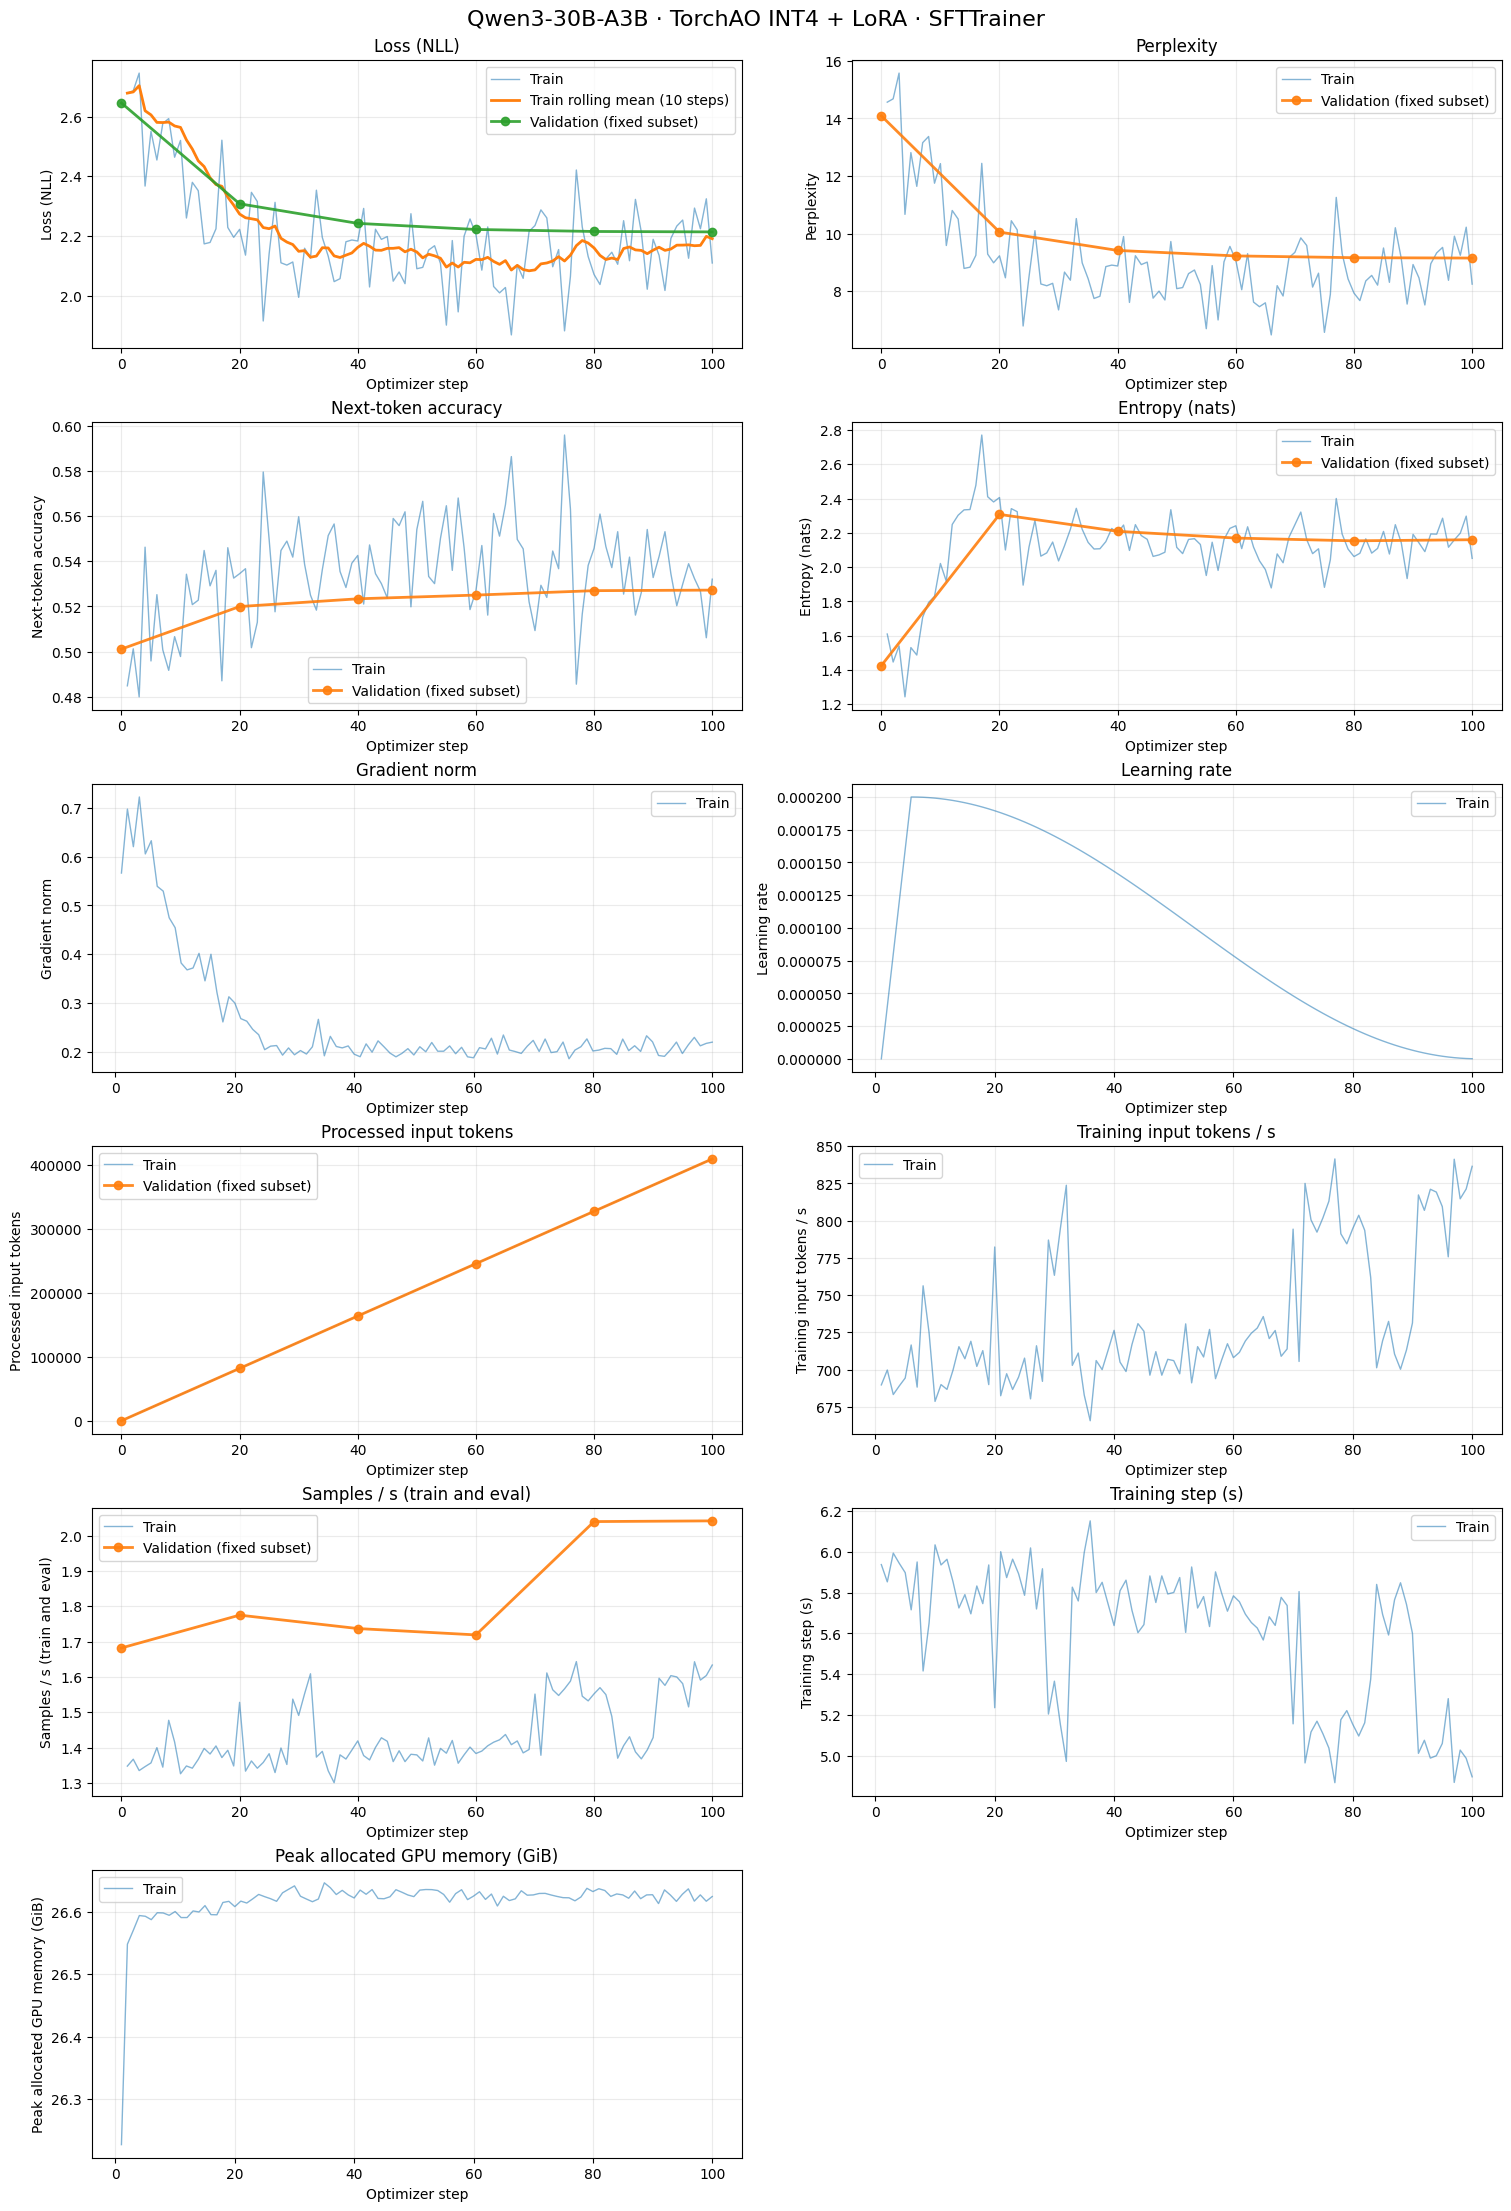

In [4]:
from train_qwen_torchao_sft import plot_training_history
import matplotlib.pyplot as plt
fig = plot_training_history(result["history"])
fig.savefig(results_dir / "training_history.png", dpi=130)
plt.show()


In [5]:
history = pd.DataFrame(result["history"])
display(history[history.eval_loss.notna()].dropna(axis=1, how="all"))
display(history[history.loss.notna()].tail(20).dropna(axis=1, how="all"))
history.to_csv(results_dir / "history.csv", index=False)
print("Full history:", results_dir / "history.json")


,eval_loss,eval_model_preparation_time,eval_runtime,eval_samples_per_second,eval_steps_per_second,eval_entropy,eval_num_tokens,eval_mean_token_accuracy,epoch,step,eval_perplexity
0,2.645524,0.4312,19.0287,1.682,0.210,1.425654,0.0,0.501101,0.00000,0,14.090830
21,2.307712,0.4312,18.0298,1.775,0.222,2.307801,81920.0,0.519936,0.15625,20,10.051402
42,2.242125,0.4312,18.4265,1.737,0.217,2.209158,163840.0,0.523361,0.31250,40,9.413316
63,2.221690,0.4312,18.6121,1.719,0.215,2.169748,245760.0,0.525012,0.46875,60,9.222906
84,2.214952,0.4312,15.6874,2.040,0.255,2.153607,327680.0,0.526969,0.62500,80,9.160974
105,2.213586,0.4312,15.6685,2.042,0.255,2.160023,409600.0,0.527214,0.78125,100,9.148463


,epoch,step,loss,grad_norm,learning_rate,entropy,num_tokens,mean_token_accuracy,perplexity,step_seconds,samples_per_second,tokens_per_second,peak_allocated_GiB,optimizer_step_skipped
85,0.632812,81,2.037258,0.203256,2.108595e-05,2.081037,331776.0,0.560910,7.669552,5.097010,1.569547,803.608312,26.636514,False
86,0.640625,82,2.122652,0.206883,1.909830e-05,2.164979,335872.0,0.546477,8.353259,5.161803,1.549846,793.521191,26.633683,False
87,0.648438,83,2.145378,0.206274,1.719912e-05,2.081957,339968.0,0.537182,8.545272,5.375358,1.488273,761.995772,26.624279,False
88,0.656250,84,2.105051,0.194539,1.539047e-05,2.109293,344064.0,0.553082,8.207522,5.840421,1.369764,701.319316,26.628189,False
89,0.664062,85,2.251063,0.225841,1.367435e-05,2.208435,348160.0,0.525440,9.497830,5.693124,1.405204,719.464414,26.626645,False
90,0.671875,86,2.116822,0.202178,1.205262e-05,2.076670,352256.0,0.541830,8.304701,5.592321,1.430533,732.432954,26.621305,False
91,0.679688,87,2.322548,0.212183,1.052707e-05,2.247759,356352.0,0.516145,10.201639,5.764867,1.387716,710.510722,26.632864,False
92,0.687500,88,2.212631,0.200568,9.099346e-06,2.143617,360448.0,0.526174,9.139727,5.848471,1.367879,700.353972,26.620611,False
93,0.695312,89,2.021480,0.232623,7.771025e-06,1.933533,364544.0,0.554061,7.549489,5.742704,1.393072,713.252892,26.626613,False
94,0.703125,90,2.188641,0.220168,6.543554e-06,2.191410,368640.0,0.532779,8.923075,5.600582,1.428423,731.352553,26.626930,False


Full history: /glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/results/torchao_sft/history.json
